In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder


In [6]:


df = pd.read_csv("D:/AQI _Analysis/Data sets/city_day.csv")

print(df.head())

        City        Date  PM2.5  PM10     NO    NO2    NOx  NH3     CO    SO2  \
0  Ahmedabad  2015-01-01    NaN   NaN   0.92  18.22  17.15  NaN   0.92  27.64   
1  Ahmedabad  2015-01-02    NaN   NaN   0.97  15.69  16.46  NaN   0.97  24.55   
2  Ahmedabad  2015-01-03    NaN   NaN  17.40  19.30  29.70  NaN  17.40  29.07   
3  Ahmedabad  2015-01-04    NaN   NaN   1.70  18.48  17.97  NaN   1.70  18.59   
4  Ahmedabad  2015-01-05    NaN   NaN  22.10  21.42  37.76  NaN  22.10  39.33   

       O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0  133.36     0.00     0.02    0.00  NaN        NaN  
1   34.06     3.68     5.50    3.77  NaN        NaN  
2   30.70     6.80    16.40    2.25  NaN        NaN  
3   36.08     4.43    10.14    1.00  NaN        NaN  
4   39.31     7.01    18.89    2.78  NaN        NaN  


In [7]:
print(df.shape)

(29531, 16)


In [8]:
print(df.columns)

Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket'],
      dtype='str')


In [9]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB
None


In [10]:
df["Date"] = pd.to_datetime(df["Date"])

In [11]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day

In [12]:
df.drop("Date", axis=1, inplace=True)

In [65]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["City"] = le.fit_transform(df["City"])

In [14]:
X = df.drop(["AQI", "AQI_Bucket"], axis=1)
y = df["AQI"]

# EDA

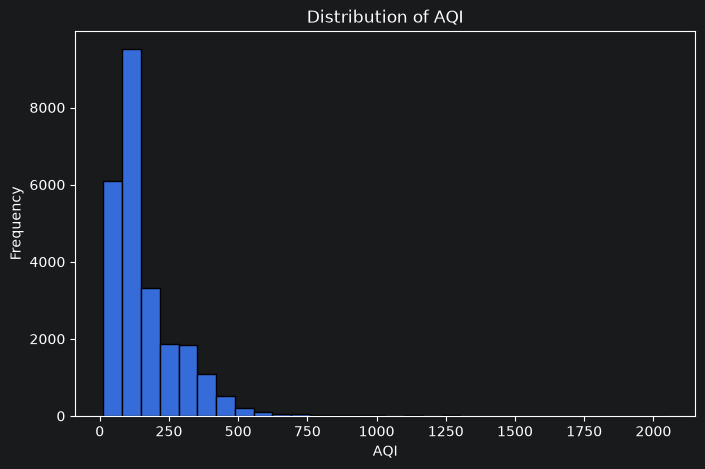

In [15]:
plt.figure(figsize=(8,5))

plt.hist(df["AQI"], bins=30, edgecolor="black")

plt.title("Distribution of AQI")

plt.xlabel("AQI")

plt.ylabel("Frequency")

plt.show()

* The AQI distribution is right-skewed.
* The dataset is not normally distributed.
* Most AQI values lie between 50 and 250.

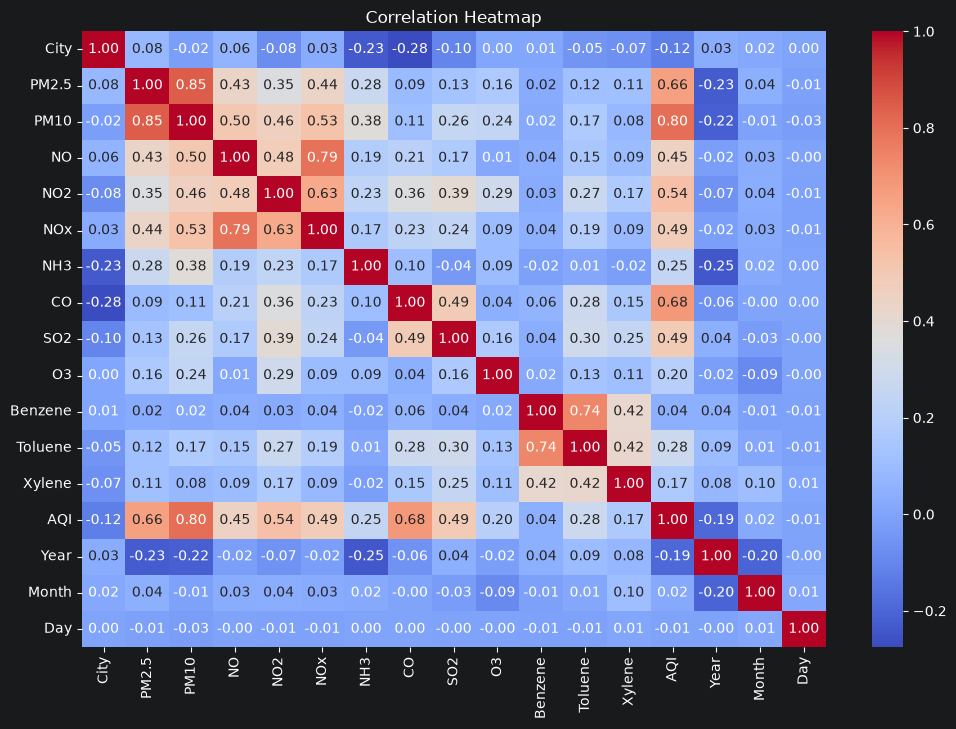

In [16]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

* PM10 has the strongest positive relationship with AQI.
* PM2.5 and CO also have strong influence.
* Benzene, Toluene and Xylene have weak linear relationships.
* PM10, PM2.5 and CO are likely to be the most influential predictors in the model.

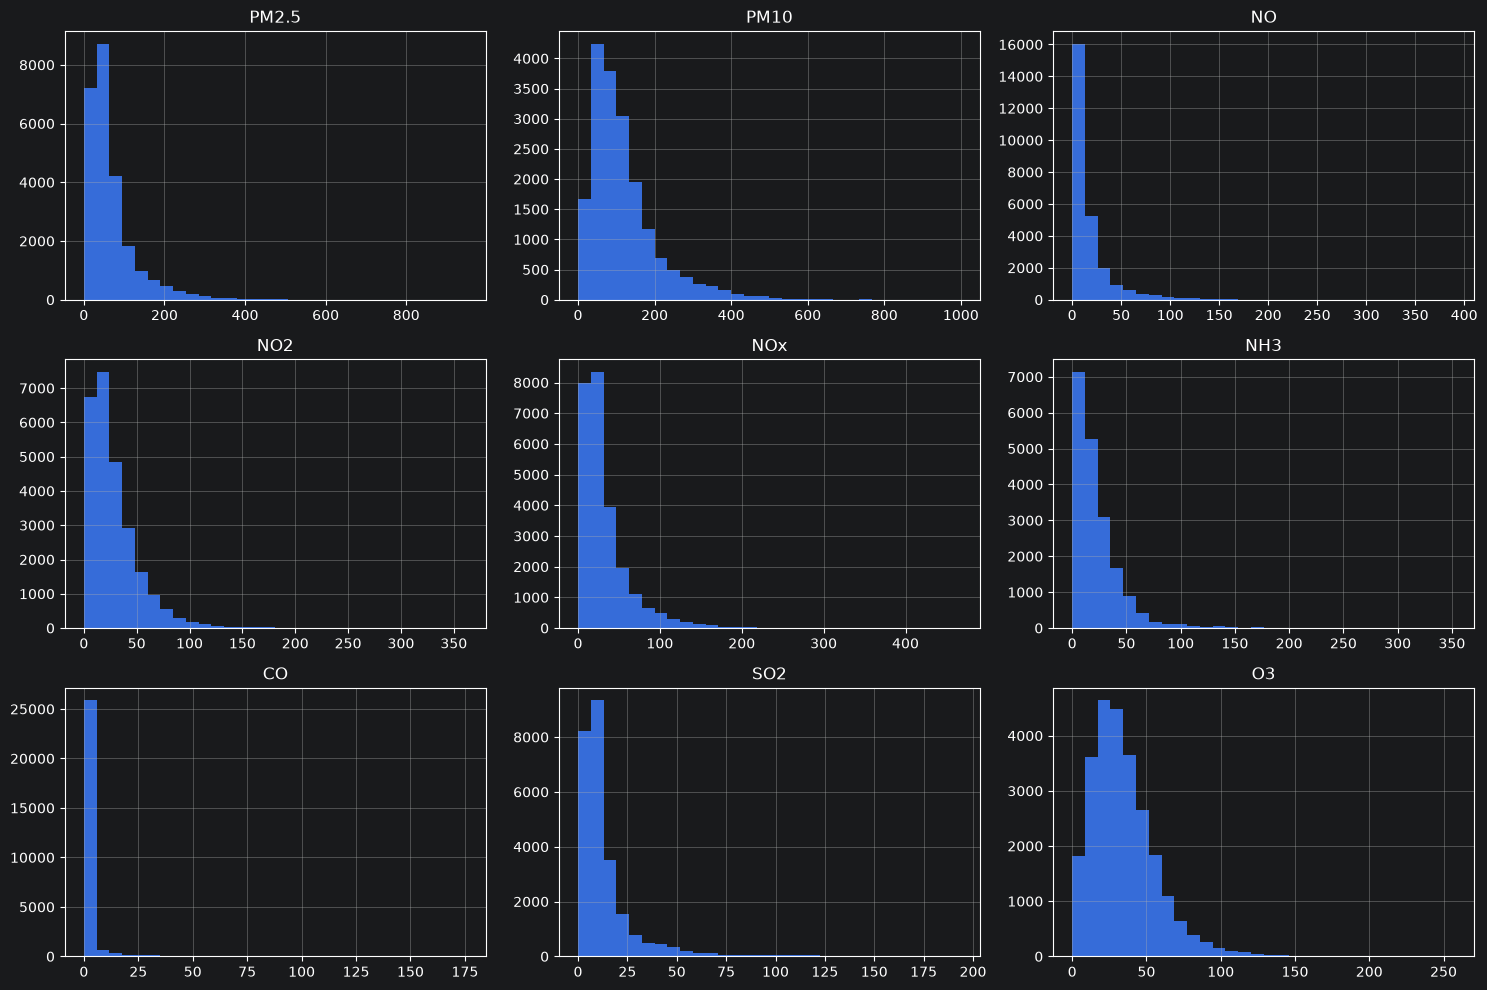

In [17]:
pollutants = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3"]

df[pollutants].hist(figsize=(15,10), bins=30)

plt.tight_layout()

plt.show()

* Most pollutant distributions are right-skewed.
* Many pollutants have long tails, meaning occasional very high pollution levels.
* CO is highly concentrated near lower values
* Air pollution values are not evenly distributed.
* Outlier handling should be considered carefully because extreme values may represent real pollution episodes.

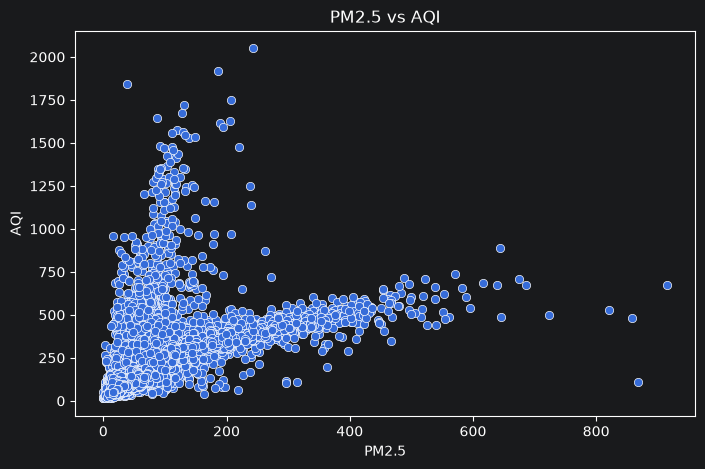

In [18]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x="PM2.5", y="AQI")

plt.title("PM2.5 vs AQI")

plt.show()

* AQI generally increases as PM2.5 increases.
* The relationship is positive but not perfectly linear.
* A few extreme AQI values exist.
* PM2.5 is an important predictor, but AQI depends on multiple pollutants, not PM2.5 alone.

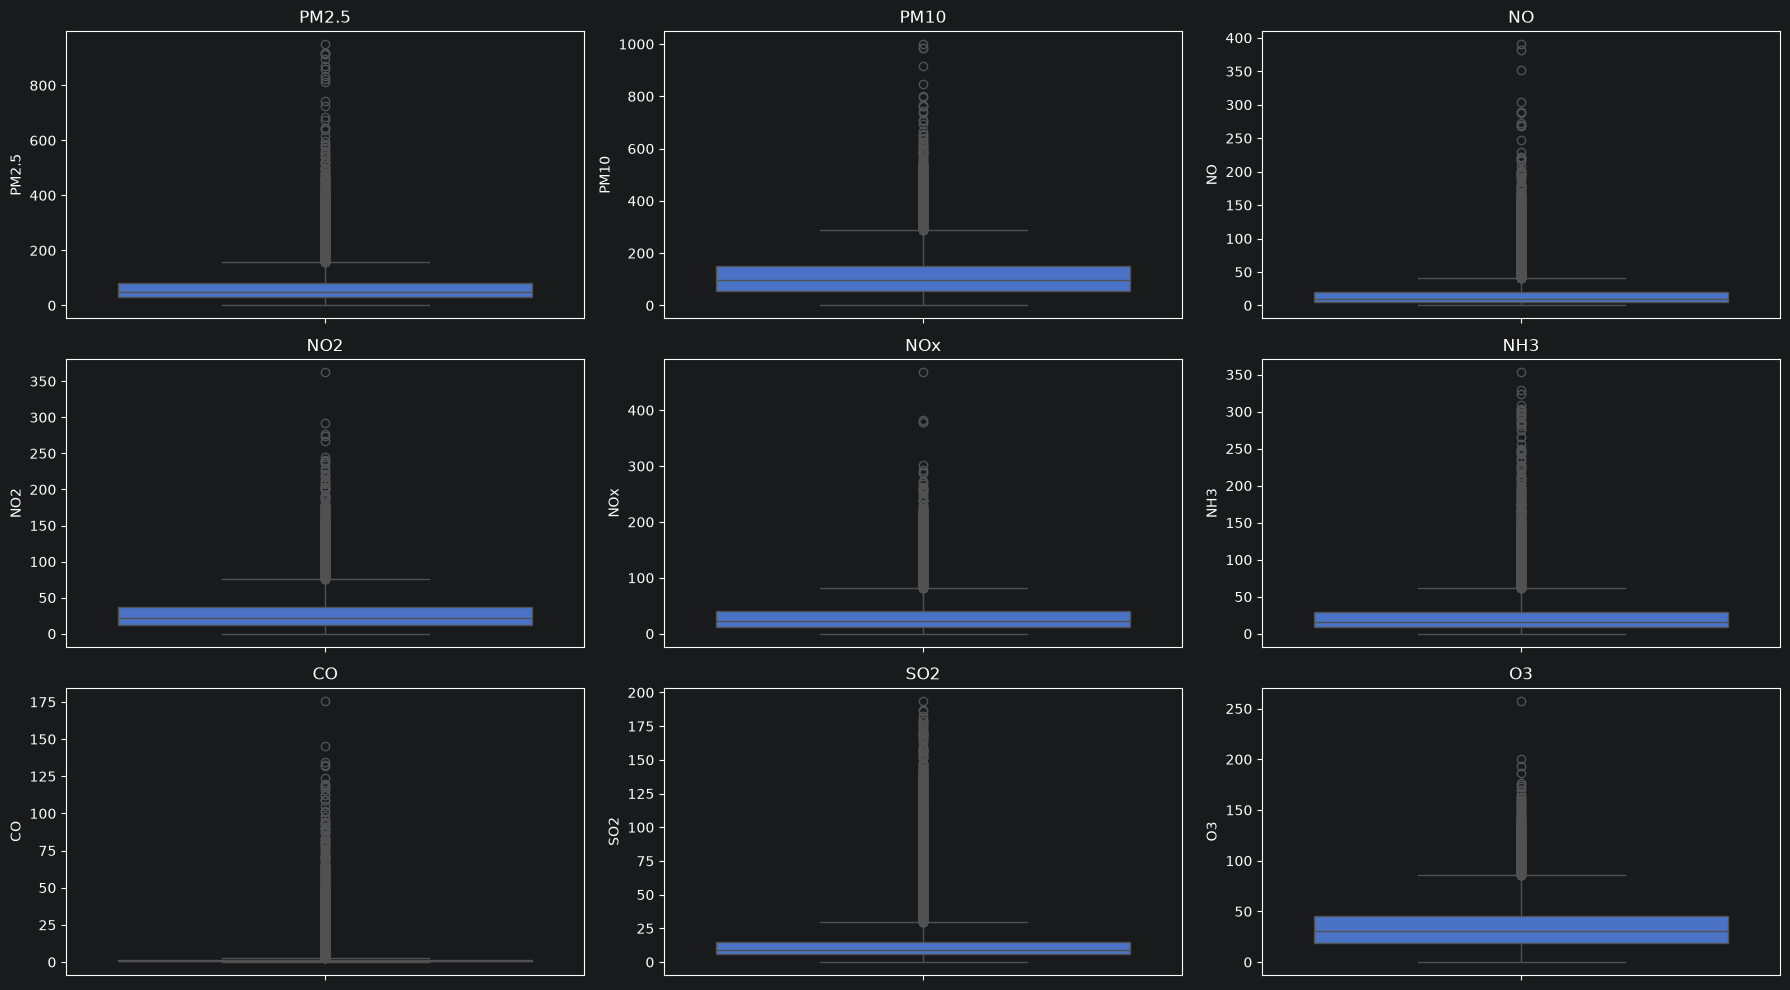

In [19]:
pollutants = ["PM2.5","PM10","NO","NO2","NOx","NH3","CO","SO2","O3"]

plt.figure(figsize=(18,10))

for i,col in enumerate(pollutants,1):
    plt.subplot(3,3,i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

* to find extreme values.
* to Decide whether to keep or remove them.

In [20]:
corr = df.corr(numeric_only=True)["AQI"].sort_values(ascending=False)

print(corr)

AQI        1.000000
PM10       0.803313
CO         0.683346
PM2.5      0.659181
NO2        0.537071
SO2        0.490586
NOx        0.486450
NO         0.452191
Toluene    0.279992
NH3        0.252019
O3         0.198991
Xylene     0.165532
Benzene    0.044407
Month      0.022163
Day       -0.005582
City      -0.123456
Year      -0.192464
Name: AQI, dtype: float64


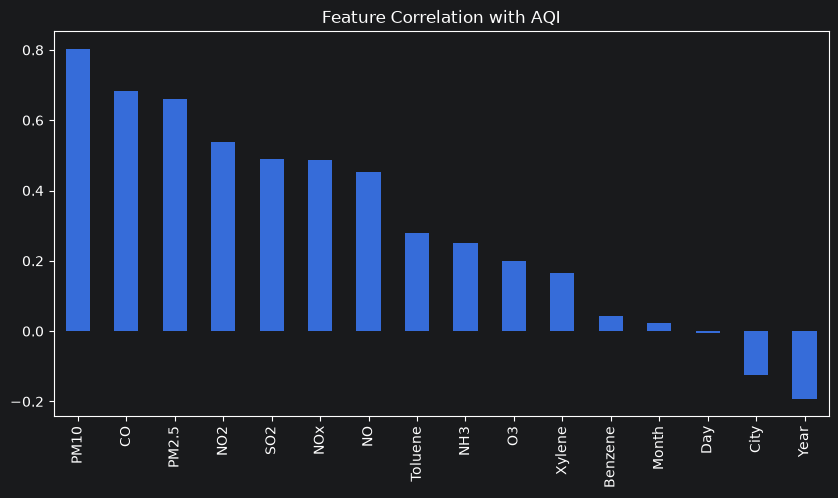

In [21]:
corr.drop("AQI").plot(kind="bar", figsize=(10,5))

plt.title("Feature Correlation with AQI")

plt.show()

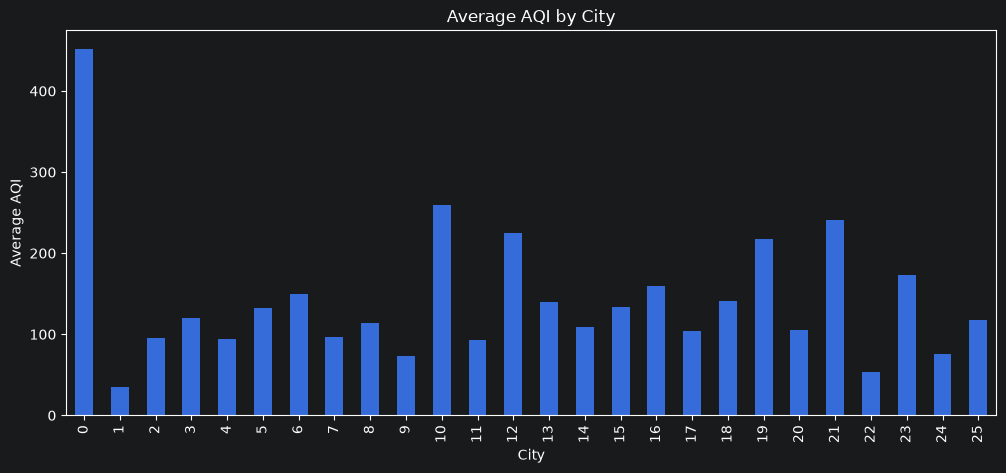

In [22]:
city_aqi = df.groupby("City")["AQI"].mean()

city_aqi.plot(kind="bar", figsize=(12,5))

plt.title("Average AQI by City")

plt.ylabel("Average AQI")

plt.show()

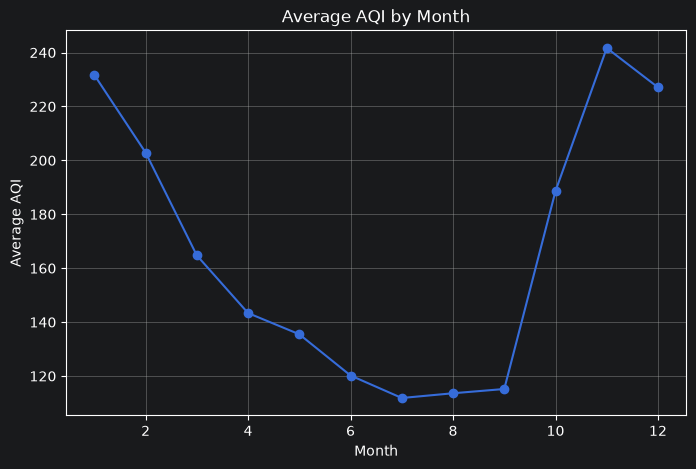

In [23]:
monthly = df.groupby("Month")["AQI"].mean()

monthly.plot(marker="o", figsize=(8,5))

plt.title("Average AQI by Month")

plt.xlabel("Month")

plt.ylabel("Average AQI")

plt.grid(True)

plt.show()

# Feature Selection

In [24]:
# Features
X = df.drop(["AQI", "AQI_Bucket"], axis=1)

# Target
y = df["AQI"]

print("Features Shape :", X.shape)
print("Target Shape :", y.shape)

Features Shape : (29531, 16)
Target Shape : (29531,)


In [25]:
df = df.dropna(subset=["AQI"])

In [26]:
X = df.drop(["AQI", "AQI_Bucket"], axis=1)
y = df["AQI"]

In [27]:
corr = df.corr(numeric_only=True)["AQI"].sort_values(ascending=False)

print(corr)

AQI        1.000000
PM10       0.803313
CO         0.683346
PM2.5      0.659181
NO2        0.537071
SO2        0.490586
NOx        0.486450
NO         0.452191
Toluene    0.279992
NH3        0.252019
O3         0.198991
Xylene     0.165532
Benzene    0.044407
Month      0.022163
Day       -0.005582
City      -0.123456
Year      -0.192464
Name: AQI, dtype: float64


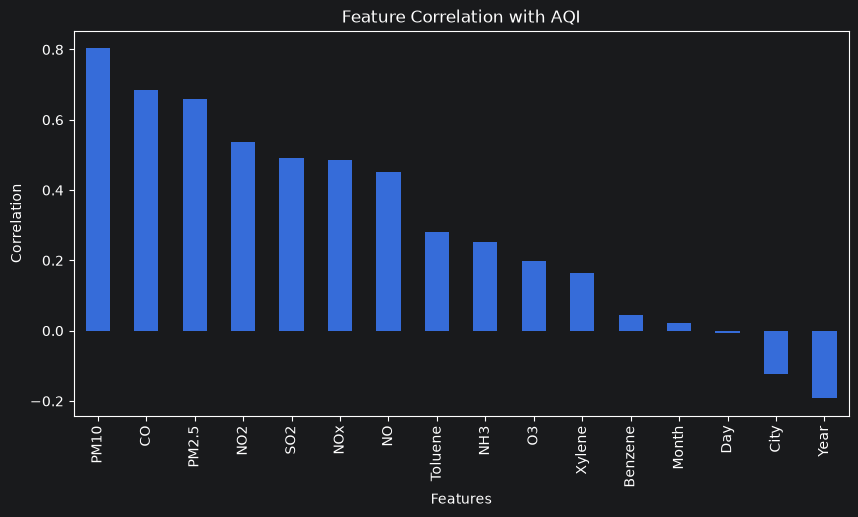

In [28]:
import matplotlib.pyplot as plt

corr.drop("AQI").plot(kind="bar", figsize=(10,5))

plt.title("Feature Correlation with AQI")
plt.xlabel("Features")
plt.ylabel("Correlation")

plt.show()

* PM10, CO, and PM2.5 show the strongest positive correlation with AQI, indicating they are likely to be the most influential features for prediction.

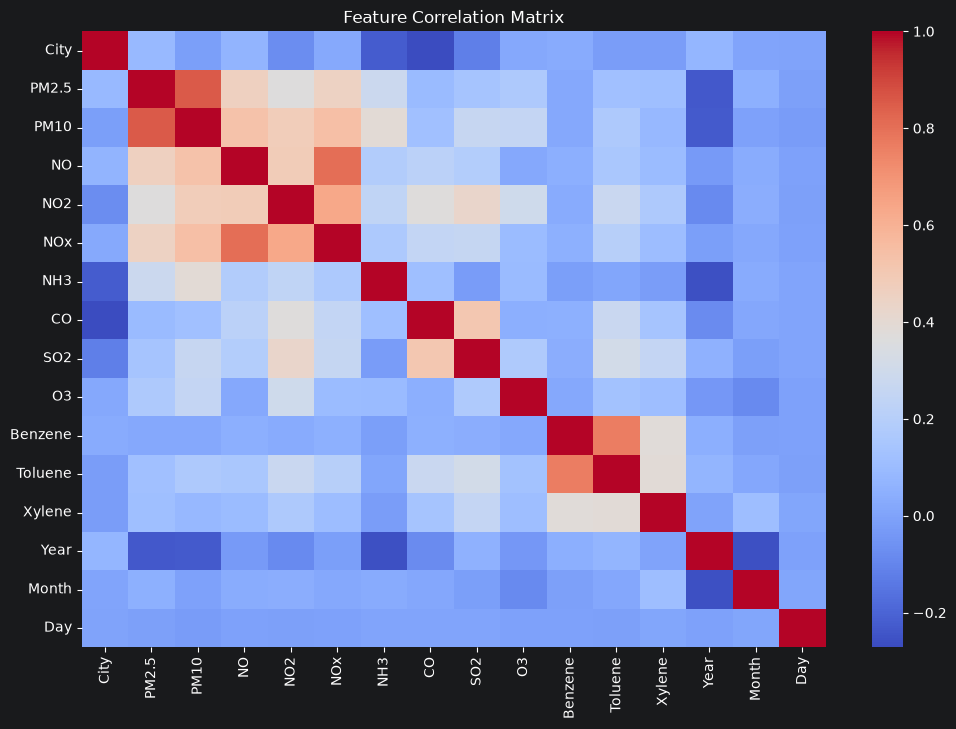

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))

sns.heatmap(X.corr(), cmap="coolwarm")

plt.title("Feature Correlation Matrix")

plt.show()

In [30]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)

rf.fit(X, y)

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)


    Feature  Importance
1     PM2.5    0.483720
7        CO    0.361210
2      PM10    0.047488
3        NO    0.033749
9        O3    0.012657
5       NOx    0.010909
8       SO2    0.008525
4       NO2    0.007061
11  Toluene    0.006302
15      Day    0.006182
12   Xylene    0.005094
10  Benzene    0.004659
13     Year    0.004069
6       NH3    0.003159
14    Month    0.002837
0      City    0.002380


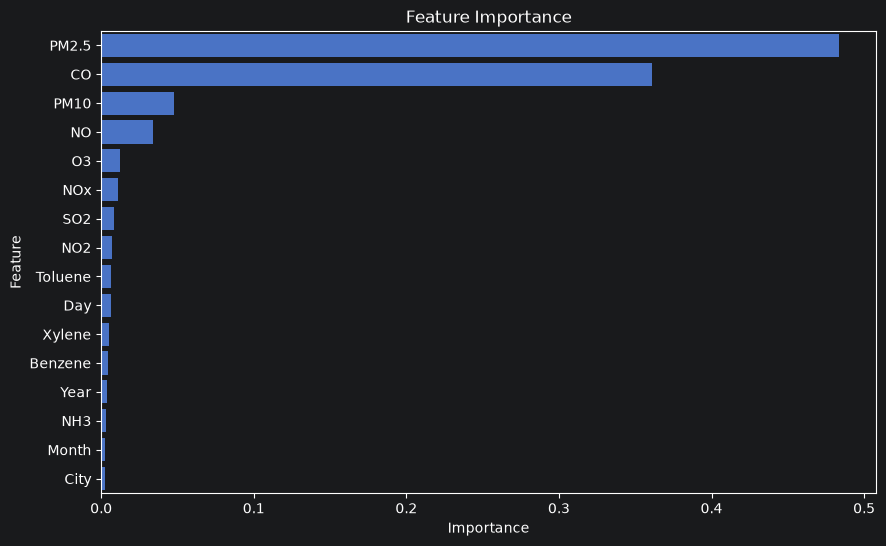

In [31]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")

plt.show()

# Train-Test Split


In [32]:
from sklearn.model_selection import train_test_split

In [33]:
# Features
X = df.drop(["AQI", "AQI_Bucket"], axis=1)
y = df["AQI"]

In [34]:
print("Object Columns:")
print(X.select_dtypes(include="object").columns)

Object Columns:
Index([], dtype='str')


In [35]:
print("Missing values in X")
print(X.isnull().sum())

print("\nMissing values in y")
print(y.isnull().sum())

Missing values in X
City           0
PM2.5        678
PM10        7086
NO           387
NO2          391
NOx         1857
NH3         6536
CO           445
SO2          605
O3           807
Benzene     3535
Toluene     5826
Xylene     15372
Year           0
Month          0
Day            0
dtype: int64

Missing values in y
0


In [36]:
X = X.fillna(X.median(numeric_only=True))

mask = y.notna()
X = X[mask]
y = y[mask]

In [37]:
print(X.isnull().sum())

City       0
PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
Year       0
Month      0
Day        0
dtype: int64


In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [39]:
df.fillna(df.median(numeric_only=True), inplace=True)

,City,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket,Year,Month,Day
28,0,83.13,96.18,6.93,28.71,33.72,16.31,6.93,49.52,59.76,0.02,0.000,3.14,209.0,Poor,2015,1,29
29,0,79.84,96.18,13.85,28.68,41.08,16.31,13.85,48.49,97.07,0.04,0.000,4.81,328.0,Very Poor,2015,1,30
30,0,94.52,96.18,24.39,32.66,52.61,16.31,24.39,67.39,111.33,0.24,0.010,7.67,514.0,Severe,2015,1,31
31,0,135.99,96.18,43.48,42.08,84.57,16.31,43.48,75.23,102.70,0.40,0.040,25.87,782.0,Severe,2015,2,1
32,0,178.33,96.18,54.56,35.31,72.80,16.31,54.56,55.04,107.38,0.46,0.060,35.61,914.0,Severe,2015,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29526,25,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.070,0.73,41.0,Good,2020,6,27
29527,25,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.210,0.38,70.0,Satisfactory,2020,6,28
29528,25,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.010,0.00,68.0,Satisfactory,2020,6,29
29529,25,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.000,0.00,54.0,Satisfactory,2020,6,30


In [40]:
X = df.drop(["AQI", "AQI_Bucket"], axis=1)
y = df["AQI"]

In [41]:
print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

(19880, 16)
(4970, 16)
(19880,)
(4970,)


In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

In [43]:
lr = LinearRegression()
lr.fit(X_train, y_train)

dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

# Model Evaluation

In [44]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
def evaluate_model(model, X_test, y_test):

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    return mae, mse, rmse, r2


In [45]:
results = []

models = {
    "Linear Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf,
    "Gradient Boosting": gb
}

for name, model in models.items():

    mae, mse, rmse, r2 = evaluate_model(
        model,
        X_test,
        y_test
    )

    results.append([
        name,
        mae,
        mse,
        rmse,
        r2
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score"
    ]
)

results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,30.994307,3513.086918,59.271299,0.808144
1,Decision Tree,28.287928,3135.145070,55.992366,0.828784
2,Random Forest,20.498652,1630.895114,40.384342,0.910934
3,Gradient Boosting,23.394266,1869.547832,43.238268,0.897900


# Hyperparameter Tuning

In [46]:
from sklearn.model_selection import GridSearchCV

In [47]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}
grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 20, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose:

In [48]:
print("Best Parameters:")
print(grid.best_params_)
best_rf = grid.best_estimator_

best_rf

Best Parameters:
{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [49]:
y_pred = best_rf.predict(X_test)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 :", r2_score(y_test, y_pred))

MAE : 20.44220891180605
RMSE: 40.3799321290099
R2 : 0.9109531410422653


In [50]:
RandomForestRegressor(random_state=42)
9RandomForestRegressor(
    n_estimators=200,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = best_rf.predict(X_test)

print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE : 20.44220891180605
RMSE: 40.3799321290099
R2 Score: 0.9109531410422653


In [51]:
import joblib

joblib.dump(best_rf, "aqi_model.pkl")

['aqi_model.pkl']

In [56]:
print(df["City"].tail())
print(df["City"].dtype)


29526    25
29527    25
29528    25
29529    25
29530    25
Name: City, dtype: int64
int64


# save city mapping


In [58]:
import pandas as pd

original_df = pd.read_csv("D:/AQI _Analysis/Data sets/city_day.csv")

city_mapping = pd.DataFrame({
    "City": original_df["City"].unique(),
    "City_ID": range(original_df["City"].nunique())
})

print(city_mapping)

                  City  City_ID
0            Ahmedabad        0
1               Aizawl        1
2            Amaravati        2
3             Amritsar        3
4            Bengaluru        4
5               Bhopal        5
6         Brajrajnagar        6
7           Chandigarh        7
8              Chennai        8
9           Coimbatore        9
10               Delhi       10
11           Ernakulam       11
12            Gurugram       12
13            Guwahati       13
14           Hyderabad       14
15              Jaipur       15
16          Jorapokhar       16
17               Kochi       17
18             Kolkata       18
19             Lucknow       19
20              Mumbai       20
21               Patna       21
22            Shillong       22
23             Talcher       23
24  Thiruvananthapuram       24
25       Visakhapatnam       25


In [60]:
city_mapping.to_csv("D:/AQI _Analysis/model/city_mapping.csv", index=False)

print("✅ City mapping saved successfully!")

✅ City mapping saved successfully!


In [67]:

joblib.dump(le,"D:/AQI _Analysis/model/city_encoder.pkl")

['D:/AQI _Analysis/model/city_encoder.pkl']